# CMP6202 – Notebook 03: Experimental design and model development

**Project:** Multi-class Classification for Cloud Network Intrusion Detection on AWS Using CSE-CIC-IDS2018

This notebook covers report sections **3.1, 3.2, 3.4** (experimental design) and **4.1–4.2** (model development and
results on "seen" data). It uses only the training set saved by notebook 02; the test set is evaluated once, in
notebook 04 (section 5).

Hyper-parameter searches take about four minutes on an M1 Max. I cache each finished search under `models/`
(git-ignored) so that re-running the notebook to update text does not refit; set `FORCE_RETRAIN = True`, or the
environment variable `NIDS_FORCE_RETRAIN=1`, to rebuild everything from scratch.

In [1]:
import os
import platform
import time

import numpy as np
import pandas as pd
from IPython.display import display

from nids import config, data, models, plotting

FORCE_RETRAIN = os.environ.get("NIDS_FORCE_RETRAIN") == "1"

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)
plotting.apply_style()


def save_text(name: str, text: str) -> None:
    # I save every copy-ready paragraph so the report quotes the code's numbers; line breaks inside a
    # paragraph are joined so the text pastes into Word cleanly.
    paragraphs = [" ".join(block.split()) for block in text.strip().split("\n\n")]
    clean = "\n\n".join(paragraphs)
    (config.TEXT_DIR / f"{name}.txt").write_text(clean + "\n")
    print(clean, f"\n\n[{len(clean.split())} words → reports/text/{name}.txt]")


sample = data.load_sample()
split = data.load_split(sample)
leakage = data.assert_no_leakage(split)
X_train, y_train = split.X_train, split.y_train
print(f"Training set: {X_train.shape[0]:,} flows; class counts {y_train.value_counts().to_dict()}")
print(f"Leakage check: {leakage}")
print(f"Machine: {platform.machine()}, {os.cpu_count()} logical CPUs; FORCE_RETRAIN={FORCE_RETRAIN}")

Training set: 60,000 flows; class counts {'Benign': 50857, 'SSH-Bruteforce': 9106, 'FTP-BruteForce': 37}
Leakage check: {'train_rows': 60000, 'test_rows': 15000, 'unique_train_vectors': 60000, 'unique_test_vectors': 15000, 'shared_vectors': 0}
Machine: arm64, 10 logical CPUs; FORCE_RETRAIN=False


# 3 Experimental Design

## 3.1 Identification of your chosen supervised learning algorithm(s)

I compare three algorithms that make different assumptions about the decision boundary, so that their differences tell
me something about the data rather than only about tuning:

* **Logistic Regression** (multinomial, L2-regularised, lbfgs solver). It fits one linear decision function per class
  and converts the scores to probabilities with the softmax function. It is the linear baseline: if it performs almost
  as well as the trees, the classes are close to linearly separable. Its coefficients are unstable when features are
  strongly correlated, which my EDA found (9 of 190 top-feature pairs with |r| ≥ 0.95), so regularisation strength `C`
  is tuned.
* **Decision Tree** (CART). It recursively splits the data on a single feature threshold that most reduces impurity
  (Gini or entropy). Threshold rules match what the EDA showed (zero payload for FTP, a fixed 640-byte packet for SSH),
  are invariant to scale and heavy tails, and are directly interpretable, but an unpruned tree over-fits, so depth and
  leaf size are tuned.
* **Random Forest** (Breiman, 2001). It averages many trees, each trained on a bootstrap sample and restricted to a
  random subset of features at every split. Averaging de-correlated trees reduces the variance of a single tree, which
  matters with only 37 FTP-BruteForce training flows.

All three are implemented in scikit-learn (Pedregosa et al., 2011) and share one imbalanced-learn pipeline
(Lemaître, Nogueira and Aridas, 2017).

In [2]:
save_text("3_1_algorithms", '''
I compare three algorithms that make different assumptions about the decision boundary. Logistic Regression
(multinomial, L2-regularised) is the linear baseline: it fits one linear score per class and converts the scores to
probabilities with the softmax function. If it performs almost as well as the trees, the classes are close to linearly
separable. Because its coefficients become unstable when inputs are strongly correlated, as the EDA found, I tune its
regularisation strength. A Decision Tree (CART) splits the data recursively on single-feature thresholds that most
reduce impurity. Such rules match the patterns found in the EDA (zero payload for FTP-BruteForce, a fixed 640-byte packet
for SSH-Bruteforce), are unaffected by scale and heavy tails, and can be read directly, but an unpruned tree over-fits,
so I tune its depth and leaf size. A Random Forest (Breiman, 2001) averages many trees, each grown on a bootstrap sample
with a random subset of features considered at every split; averaging de-correlated trees reduces the variance of a
single tree, which matters with only 37 FTP-BruteForce training flows. All three are implemented in scikit-learn
(Pedregosa et al., 2011) inside one imbalanced-learn pipeline (Lemaître, Nogueira and Aridas, 2017).
''')

I compare three algorithms that make different assumptions about the decision boundary. Logistic Regression (multinomial, L2-regularised) is the linear baseline: it fits one linear score per class and converts the scores to probabilities with the softmax function. If it performs almost as well as the trees, the classes are close to linearly separable. Because its coefficients become unstable when inputs are strongly correlated, as the EDA found, I tune its regularisation strength. A Decision Tree (CART) splits the data recursively on single-feature thresholds that most reduce impurity. Such rules match the patterns found in the EDA (zero payload for FTP-BruteForce, a fixed 640-byte packet for SSH-Bruteforce), are unaffected by scale and heavy tails, and can be read directly, but an unpruned tree over-fits, so I tune its depth and leaf size. A Random Forest (Breiman, 2001) averages many trees, each grown on a bootstrap sample with a random subset of features considered at every split; a

## 3.2 Identification of appropriate evaluation techniques

| Technique | Why I use it here |
|---|---|
| **Weighted F1** | Selection metric required by the brief; averages per-class F1 weighted by class size. |
| **Macro F1, macro precision, macro recall** | Every class counts equally, so the 0.06% FTP class can move the score; weighted F1 can stay near 1.0 while FTP is missed. |
| **Recall of FTP-BruteForce** | The cost of a missed attack is the main risk for an intrusion detector. |
| **Confusion matrix** | Shows *which* classes are confused and how many false alarms each model raises. |
| **5-fold stratified CV (shuffled, fixed seed)** | Every model is scored on the same folds; I report mean ± standard deviation and per-fold scores. |
| **Out-of-fold predictions** | A confusion matrix on the training set in which every flow is predicted by a model that did not see it. |
| **Training and inference time** | Needed for the comparative analysis and for deployment on cloud infrastructure. |

In [3]:
save_text("3_2_evaluation", '''
Accuracy is not informative here: a classifier that never predicts FTP-BruteForce would still reach 99.94% accuracy on
the training set. The brief requires weighted F1, which I use to select hyper-parameters, but weighted F1 is dominated by
the Benign class (85% of flows). I therefore also report macro-averaged F1, precision and recall, in which every class
counts equally, and the recall of FTP-BruteForce on its own, because a missed attack is the costliest error for an
intrusion detector. Confusion matrices show which classes are confused and how many false alarms each model raises.
All models are evaluated with the same 5-fold stratified cross-validation (shuffled with seed 42) on the training set,
reported as mean ± standard deviation across folds; random rather than exhaustive search samples 20 settings per model
at a fraction of the cost (Bergstra and Bengio, 2012). Out-of-fold predictions give a confusion matrix on "seen" data in
which no flow is predicted by a model trained on it. I also time training and inference, because a detector on cloud
infrastructure must keep up with traffic. The held-out test set is used once, for the final comparison in section 5.
''')

Accuracy is not informative here: a classifier that never predicts FTP-BruteForce would still reach 99.94% accuracy on the training set. The brief requires weighted F1, which I use to select hyper-parameters, but weighted F1 is dominated by the Benign class (85% of flows). I therefore also report macro-averaged F1, precision and recall, in which every class counts equally, and the recall of FTP-BruteForce on its own, because a missed attack is the costliest error for an intrusion detector. Confusion matrices show which classes are confused and how many false alarms each model raises. All models are evaluated with the same 5-fold stratified cross-validation (shuffled with seed 42) on the training set, reported as mean ± standard deviation across folds; random rather than exhaustive search samples 20 settings per model at a fraction of the cost (Bergstra and Bengio, 2012). Out-of-fold predictions give a confusion matrix on "seen" data in which no flow is predicted by a model trained on i

## 3.4 Limitations and Options

The limitations below come from the data and from my design choices; section 5 tests the ones that can be tested.

In [4]:
save_text("3_4_limitations", '''
The dataset covers one day and two attack types, so the models learn to separate SSH and FTP brute force from that
day's benign traffic, not intrusions in general. After de-duplication only 46 FTP-BruteForce flows remain (9 in the test
set), so its per-class scores rest on very few examples and SMOTE can only interpolate between them. The labels were
created from the attack schedule, ports and IP addresses, and both attacks share the same initial TCP window
(26,883 bytes) set by the attacking machines, so a model may learn the labelling procedure or the attacking hosts rather
than attack behaviour; I
exclude Dst Port and Timestamp and test both shortcuts with ablations. The split is random, not by time or host: flows of
the same attack session can fall in both partitions, which is optimistic, and this file contains no IP columns that would
allow a host-grouped split. Finally, the file stops at the Excel row limit and may be truncated. Options include a
time-based split, adding further CSE-CIC-IDS2018 days and attack types, and comparing with cost-sensitive learning
(class weights) instead of SMOTE.
''')

The dataset covers one day and two attack types, so the models learn to separate SSH and FTP brute force from that day's benign traffic, not intrusions in general. After de-duplication only 46 FTP-BruteForce flows remain (9 in the test set), so its per-class scores rest on very few examples and SMOTE can only interpolate between them. The labels were created from the attack schedule, ports and IP addresses, and both attacks share the same initial TCP window (26,883 bytes) set by the attacking machines, so a model may learn the labelling procedure or the attacking hosts rather than attack behaviour; I exclude Dst Port and Timestamp and test both shortcuts with ablations. The split is random, not by time or host: flows of the same attack session can fall in both partitions, which is optimistic, and this file contains no IP columns that would allow a host-grouped split. Finally, the file stops at the Excel row limit and may be truncated. Options include a time-based split, adding further 

# 4 Predictive Modelling / Model Development

## 4.1 The predictive modelling process

**Pipeline.** Every model is the same imbalanced-learn pipeline (`src/nids/features.py`):

```
ColumnTransformer ── Protocol → OneHotEncoder
                 └─ numeric  → [symlog or passthrough] → VarianceThreshold(0) → StandardScaler
      → SMOTE (FTP-BruteForce only, capped)  → classifier
```

imbalanced-learn applies SMOTE only while fitting, so synthetic flows are generated from each training fold alone and
never reach a validation fold or the test set.

**Step 1 – Baseline.** Each algorithm with scikit-learn's default hyper-parameters and *without* SMOTE, scored on the
same five folds. This is the reference that tuning has to beat.

In [5]:
defaults = models.default_estimators()
default_params = pd.DataFrame({
    name: {k: v for k, v in est.get_params().items()
           if k in ("C", "max_iter", "solver", "l1_ratio", "criterion", "max_depth", "min_samples_leaf",
                    "n_estimators", "max_features", "bootstrap")}
    for name, est in defaults.items()
}).T
display(default_params.fillna("–"))

baseline = {}
for name in models.MODEL_NAMES:
    start = time.perf_counter()
    baseline[name] = models.baseline_cv(name, X_train, y_train)
    print(f"{name:20s} baseline CV in {time.perf_counter() - start:5.1f} s")

,C,l1_ratio,max_iter,solver,criterion,max_depth,max_features,min_samples_leaf,bootstrap,n_estimators
Logistic Regression,1.0,0.0,2000,lbfgs,–,–,–,–,–,–
Decision Tree,–,–,–,–,gini,–,–,1,–,–
Random Forest,–,–,–,–,gini,–,sqrt,1,True,100


Logistic Regression  baseline CV in   3.9 s


Decision Tree        baseline CV in   3.2 s


Random Forest        baseline CV in   6.2 s


**Step 2 – Randomised hyper-parameter search.** For each algorithm `RandomizedSearchCV` samples 20 settings from the
distributions below (100 fits per model with 5-fold CV), scores every metric, and refits the setting with the highest
mean weighted F1 on the whole training set. The SMOTE target size for FTP-BruteForce (500, 1,000 or 2,000) and its
`k_neighbors` (3 or 5, below the ~30 FTP flows in a fold) are searched together with the model parameters.

In [6]:
space_table = pd.DataFrame([
    {"model": name, "parameter": param.replace("model__", "").replace("resample__", "SMOTE ")
                                      .replace("preprocess__numeric__log", "numeric transform"),
     "values searched": (f"{dist.dist.name}({dist.args[0]:g}, {dist.args[1]:g})" if hasattr(dist, "dist")
                         else ", ".join("symlog" if callable(getattr(v, "func", None)) else str(v) for v in dist))}
    for name, space in models.search_spaces().items() for param, dist in space.items()
])
display(space_table)
space_table.to_csv(config.TABLES_DIR / "4_1_search_spaces.csv", index=False)

runs = {}
for name in models.MODEL_NAMES:
    start = time.perf_counter()
    runs[name] = models.load_or_run_search(name, X_train, y_train, force=FORCE_RETRAIN)
    source = "trained" if time.perf_counter() - start > 5 else "loaded from cache"
    print(f"{name:20s} search {runs[name].search_seconds:6.1f} s ({source})")

,model,parameter,values searched
0,Logistic Regression,C,"loguniform(0.001, 100)"
1,Logistic Regression,numeric transform,"passthrough, symlog"
2,Logistic Regression,SMOTE sampling_strategy,"{'FTP-BruteForce': 500}, {'FTP-BruteForce': 1000}, {'FTP-BruteForce': 2000}"
3,Logistic Regression,SMOTE k_neighbors,"3, 5"
4,Decision Tree,max_depth,"None, 5, 10, 15, 20, 30"
5,Decision Tree,min_samples_leaf,"randint(1, 30)"
6,Decision Tree,criterion,"gini, entropy"
7,Decision Tree,SMOTE sampling_strategy,"{'FTP-BruteForce': 500}, {'FTP-BruteForce': 1000}, {'FTP-BruteForce': 2000}"
8,Decision Tree,SMOTE k_neighbors,"3, 5"
9,Random Forest,n_estimators,"randint(100, 401)"


Logistic Regression  search   30.2 s (loaded from cache)
Decision Tree        search   20.4 s (loaded from cache)
Random Forest        search  176.3 s (loaded from cache)


,model,parameter,selected value
0,Logistic Regression,C,1.2229
1,Logistic Regression,numeric transform,symlog
2,Logistic Regression,SMOTE k_neighbors,5
3,Logistic Regression,SMOTE sampling_strategy,500 FTP flows
4,Decision Tree,criterion,entropy
5,Decision Tree,max_depth,None
6,Decision Tree,min_samples_leaf,4
7,Decision Tree,SMOTE k_neighbors,5
8,Decision Tree,SMOTE sampling_strategy,"1,000 FTP flows"
9,Random Forest,max_depth,20


,model,search_seconds,fit_seconds,predict_ms_per_1000
0,Logistic Regression,30.209,0.778,1.234
1,Decision Tree,20.354,0.472,0.369
2,Random Forest,176.268,3.764,2.707


PosixPath('<project>/reports/figures/4_1_training_inference_time.png')

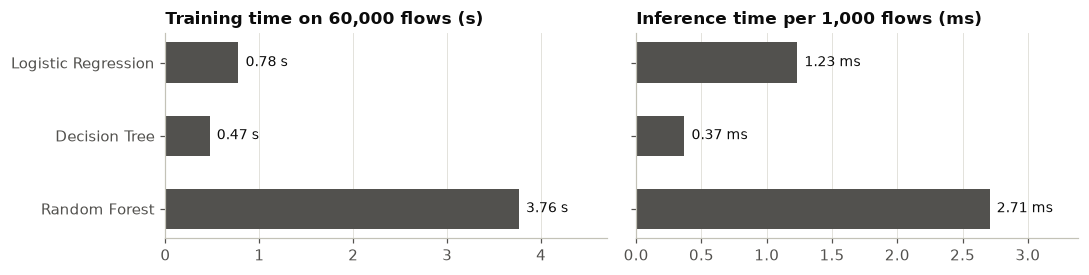

In [7]:
def readable(value):
    if callable(getattr(value, "func", None)):
        return "symlog"
    if isinstance(value, dict):
        return f"{next(iter(value.values())):,} FTP flows"
    return round(value, 4) if isinstance(value, float) else value

best_params = pd.DataFrame([
    {"model": name, "parameter": k.replace("model__", "").replace("resample__", "SMOTE ")
                                  .replace("preprocess__numeric__log", "numeric transform"),
     "selected value": readable(v)}
    for name, run in runs.items() for k, v in run.search.best_params_.items()
])
display(best_params)
best_params.to_csv(config.TABLES_DIR / "4_1_best_params.csv", index=False)

timing = pd.DataFrame([
    {"model": name, "search_seconds": run.search_seconds, "fit_seconds": run.fit_seconds,
     "predict_ms_per_1000": run.predict_ms_per_1000}
    for name, run in runs.items()
])
display(timing.round(3))
timing.round(4).to_csv(config.TABLES_DIR / "4_1_timing.csv", index=False)
fig = plotting.plot_timing(timing)
plotting.save_figure(fig, "4_1_training_inference_time")

**How decisive was the selection metric?** If many settings score within one standard deviation of the best weighted
F1, the search could not really tell them apart and the "best" setting is close to an arbitrary pick among ties.

In [8]:
ties = []
for name, run in runs.items():
    res, best = run.search.cv_results_, run.search.best_index_
    best_mean, best_std = res["mean_test_f1_weighted"][best], res["std_test_f1_weighted"][best]
    within = res["mean_test_f1_weighted"] >= best_mean - best_std
    ties.append({
        "model": name,
        "best weighted F1": best_mean,
        "settings within 1 SD": int(within.sum()),
        "macro F1 range among them": f"{res['mean_test_f1_macro'][within].min():.4f}–{res['mean_test_f1_macro'][within].max():.4f}",
        "best macro F1 of all settings": res["mean_test_f1_macro"].max(),
    })
ties = pd.DataFrame(ties)
display(ties.round(5))
ties.to_csv(config.TABLES_DIR / "4_1_selection_ties.csv", index=False)

,model,best weighted F1,settings within 1 SD,macro F1 range among them,best macro F1 of all settings
0,Logistic Regression,0.99985,7,0.9525–0.9837,0.98368
1,Decision Tree,0.99985,6,0.9663–0.9953,0.99534
2,Random Forest,0.99993,13,0.9954–0.9955,0.99549


In [9]:
def describe(name):
    params = best_params[best_params["model"] == name]
    return ", ".join(f"{p} = {v}" for p, v in zip(params["parameter"], params["selected value"]))

t = timing.set_index("model")
tie = ties.set_index("model")
save_text("4_1_modelling_process", f'''
Every model is the same imbalanced-learn pipeline: Protocol is one-hot encoded; the numeric features pass through an
optional symlog transform, a filter that drops constant columns and a StandardScaler; SMOTE then oversamples
FTP-BruteForce; finally the classifier is fitted. Because imbalanced-learn applies SMOTE only during fitting, synthetic
flows are generated from each training fold and never reach a validation fold. I first scored each algorithm with
scikit-learn's default hyper-parameters and without SMOTE (Logistic Regression needed max_iter = 2,000 to converge).
I then tuned each algorithm with RandomizedSearchCV: 20 settings × 5 stratified folds = 100 fits per model, with the
SMOTE target size and neighbour count searched alongside the model parameters, and the best mean weighted F1 refitted
on all 60,000 training flows. The selected settings were: Logistic Regression ({describe("Logistic Regression")});
Decision Tree ({describe("Decision Tree")}); Random Forest ({describe("Random Forest")}). On an M1 Max (10 cores, folds in
parallel) the searches took {t.loc["Logistic Regression", "search_seconds"]:.0f} s, {t.loc["Decision Tree", "search_seconds"]:.0f} s
and {t.loc["Random Forest", "search_seconds"]:.0f} s; refitting the selected model took {t.loc["Logistic Regression", "fit_seconds"]:.2f} s,
{t.loc["Decision Tree", "fit_seconds"]:.2f} s and {t.loc["Random Forest", "fit_seconds"]:.2f} s, and inference took
{t.loc["Logistic Regression", "predict_ms_per_1000"]:.2f}, {t.loc["Decision Tree", "predict_ms_per_1000"]:.2f} and
{t.loc["Random Forest", "predict_ms_per_1000"]:.2f} ms per 1,000 flows (Figure 4.1). Weighted F1 barely discriminated
between settings: {tie.loc["Logistic Regression", "settings within 1 SD"]}, {tie.loc["Decision Tree", "settings within 1 SD"]} and
{tie.loc["Random Forest", "settings within 1 SD"]} of the 20 settings scored within one standard deviation of the best.
''')

Every model is the same imbalanced-learn pipeline: Protocol is one-hot encoded; the numeric features pass through an optional symlog transform, a filter that drops constant columns and a StandardScaler; SMOTE then oversamples FTP-BruteForce; finally the classifier is fitted. Because imbalanced-learn applies SMOTE only during fitting, synthetic flows are generated from each training fold and never reach a validation fold. I first scored each algorithm with scikit-learn's default hyper-parameters and without SMOTE (Logistic Regression needed max_iter = 2,000 to converge). I then tuned each algorithm with RandomizedSearchCV: 20 settings × 5 stratified folds = 100 fits per model, with the SMOTE target size and neighbour count searched alongside the model parameters, and the best mean weighted F1 refitted on all 60,000 training flows. The selected settings were: Logistic Regression (C = 1.2229, numeric transform = symlog, SMOTE k_neighbors = 5, SMOTE sampling_strategy = 500 FTP flows); Deci

## 4.2 Evaluation results on "seen" data

"Seen" here means the training set, evaluated in two ways: the **validation folds** of cross-validation (each scored
by a model trained on the other four folds) and the **training folds** themselves (scored by the model that was
fitted on them). The gap between the two shows over-fitting.

validation_mean  validation_std  train_mean  train_std
model               metric                                                                 
Logistic Regression accuracy                  0.9998          0.0001      0.9999     0.0000
                    f1_weighted               0.9999          0.0001      0.9999     0.0000
                    f1_macro                  0.9793          0.0133      0.9778     0.0018
                    recall_macro              0.9999          0.0002      0.9999     0.0000
                    precision_macro           0.9620          0.0235      0.9586     0.0032
                    recall_ftp                1.0000          0.0000      1.0000     0.0000
Decision Tree       accuracy                  0.9998          0.0001      0.9999     0.0000
                    f1_weighted               0.9999          0.0001      0.9999     0.0000
                    f1_macro                  0.9903          0.0192      0.9999     0.0000
                    recall_macro              0.9903          0.0191      0.9999     0.0000
                    precision_macro           0.9903          0.0192      0.9999     0.0000
                    recall_ftp                0.9714          0.0571      1.0000     0.0000
Random Forest       accuracy                  0.9999          0.0001      1.0000     0.0000
                    f1_weighted               0.9999          0.0001      1.0000     0.0000
                    f1_macro                  0.9955          0.0089      1.0000     0.0000
                    recall_macro              0.9999          0.0002      1.0000     0.0000
                    precision_macro           0.9916          0.0167      1.0000     0.0000
                    recall_ftp                1.0000          0.0000      1.0000     0.0000

metric              f1_macro         f1_weighted         recall_ftp        
stage               Baseline   Tuned    Baseline   Tuned   Baseline   Tuned
model                                                                      
Decision Tree         0.9954  0.9903      0.9999  0.9999        1.0  0.9714
Logistic Regression   0.9718  0.9793      0.9998  0.9999        1.0  1.0000
Random Forest         0.9955  0.9955      0.9999  0.9999        1.0  1.0000

PosixPath('<project>/reports/figures/4_2_cv_baseline_vs_tuned.png')

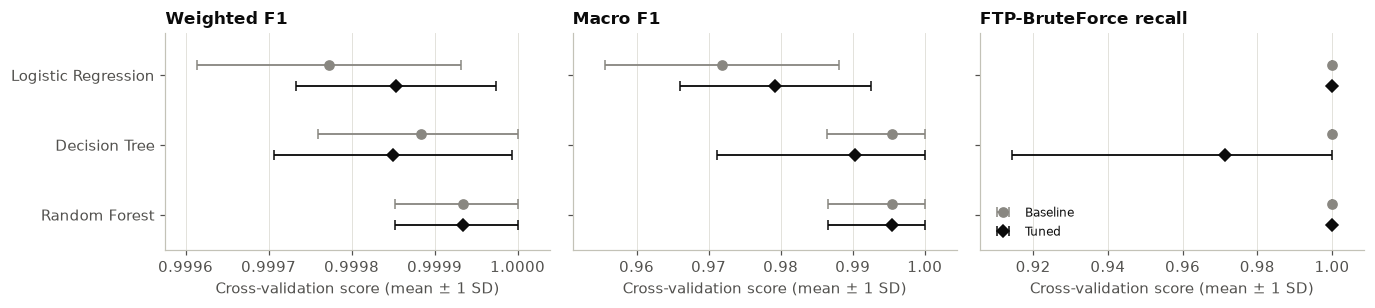

In [10]:
summaries = {name: models.best_cv_summary(run) for name, run in runs.items()}
summary_table = pd.concat(summaries, names=["model", "metric"]).round(4)
display(summary_table)
summary_table.to_csv(config.TABLES_DIR / "4_2_cv_summary.csv")

metrics_shown = {"f1_weighted": "Weighted F1", "f1_macro": "Macro F1", "recall_ftp": "FTP-BruteForce recall"}
rows = []
for name in models.MODEL_NAMES:
    for metric in metrics_shown:
        rows.append({"model": name, "stage": "Baseline", "metric": metric,
                     "mean": baseline[name][f"test_{metric}"].mean(), "std": baseline[name][f"test_{metric}"].std(ddof=0)})
        s = summaries[name].loc[metric]
        rows.append({"model": name, "stage": "Tuned", "metric": metric,
                     "mean": s["validation_mean"], "std": s["validation_std"]})
comparison = pd.DataFrame(rows)
comparison.round(5).to_csv(config.TABLES_DIR / "4_2_baseline_vs_tuned.csv", index=False)
display(comparison.pivot_table(index="model", columns=["metric", "stage"], values="mean").round(4))

fig = plotting.plot_cv_comparison(comparison, metrics_shown)
plotting.save_figure(fig, "4_2_cv_baseline_vs_tuned")

Logistic Regression            Decision Tree            Random Forest           
                  f1_macro recall_ftp      f1_macro recall_ftp      f1_macro recall_ftp
fold 1              0.9582        1.0        0.9519     0.8571        0.9777        1.0
fold 2              1.0000        1.0        0.9999     1.0000        1.0000        1.0
fold 3              0.9778        1.0        1.0000     1.0000        1.0000        1.0
fold 4              0.9801        1.0        0.9998     1.0000        0.9998        1.0
fold 5              0.9804        1.0        0.9999     1.0000        1.0000        1.0

,model,true,predicted,flows
0,Logistic Regression,Benign,FTP-BruteForce,5
1,Logistic Regression,Benign,SSH-Bruteforce,1
4,Logistic Regression,SSH-Bruteforce,Benign,3
6,Decision Tree,Benign,FTP-BruteForce,1
7,Decision Tree,Benign,SSH-Bruteforce,4
9,Decision Tree,FTP-BruteForce,SSH-Bruteforce,1
10,Decision Tree,SSH-Bruteforce,Benign,3
12,Random Forest,Benign,FTP-BruteForce,1
16,Random Forest,SSH-Bruteforce,Benign,3


SSH flows predicted as Benign by all three models: 3


,Protocol,Flow Duration,Tot Fwd Pkts,Tot Bwd Pkts,TotLen Fwd Pkts,Fwd Pkt Len Max,Init Fwd Win Byts
27716,6.0,7.0,1.0,1.0,0.0,0.0,241.0
39040,6.0,12.0,1.0,1.0,0.0,0.0,241.0
41603,6.0,18501.0,2.0,0.0,0.0,0.0,241.0


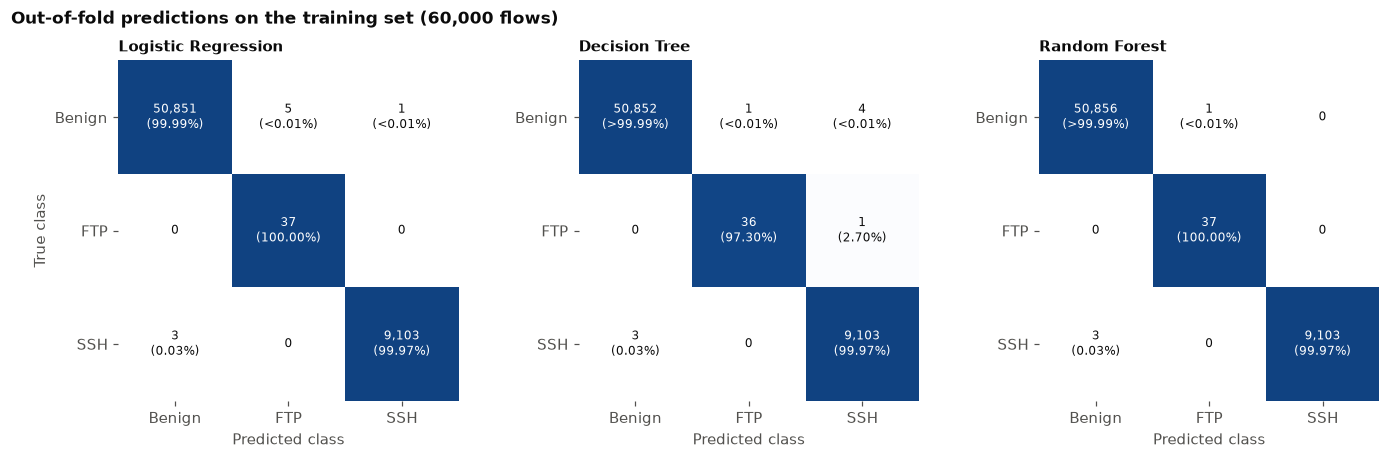

In [11]:
folds = pd.DataFrame({
    (name, metric): models.fold_scores(run, metric)
    for name, run in runs.items() for metric in ("f1_macro", "recall_ftp")
}, index=[f"fold {k + 1}" for k in range(config.CV_FOLDS)]).round(4)
display(folds)
folds.to_csv(config.TABLES_DIR / "4_2_fold_scores.csv")

oof = {}
for name, run in runs.items():
    oof[name] = (y_train.to_numpy(), models.out_of_fold_predictions(run, X_train, y_train))
fig = plotting.plot_confusion_matrices(oof, "Out-of-fold predictions on the training set (60,000 flows)")
plotting.save_figure(fig, "4_2_confusion_matrices_out_of_fold")

errors = pd.DataFrame([
    {"model": name, "true": t, "predicted": p, "flows": int(((yt == t) & (yp == p)).sum())}
    for name, (yt, yp) in oof.items() for t in plotting.CLASS_ORDER for p in plotting.CLASS_ORDER if t != p
])
errors = errors[errors["flows"] > 0]
display(errors)
errors.to_csv(config.TABLES_DIR / "4_2_out_of_fold_errors.csv", index=False)

# Are the SSH flows predicted as Benign the same flows for every model? If so, the difficulty lies in
# those flows, not in any one algorithm.
missed_ssh = [set(np.flatnonzero((yt == "SSH-Bruteforce") & (yp == "Benign"))) for yt, yp in oof.values()]
shared_missed_ssh = set.intersection(*missed_ssh)
print(f"SSH flows predicted as Benign by all three models: {len(shared_missed_ssh)}")
missed_windows = X_train.iloc[sorted(shared_missed_ssh)]["Init Fwd Win Byts"].tolist()
display(X_train.iloc[sorted(shared_missed_ssh)][["Protocol", "Flow Duration", "Tot Fwd Pkts", "Tot Bwd Pkts",
                                                   "TotLen Fwd Pkts", "Fwd Pkt Len Max", "Init Fwd Win Byts"]])

In [12]:
def err(name):
    rows = errors[errors["model"] == name]
    if rows.empty:
        return "no errors"
    return "; ".join(f"{r.flows} {r.true} as {r.predicted}" for r in rows.itertuples())

def ms(name, metric, column="validation"):
    s = summaries[name].loc[metric]
    return f"{s[f'{column}_mean']:.4f} ± {s[f'{column}_std']:.4f}"

base = {name: baseline[name]["test_f1_macro"].mean() for name in models.MODEL_NAMES}
tuned = {name: summaries[name].loc["f1_macro", "validation_mean"] for name in models.MODEL_NAMES}
total_errors = errors.groupby("model")["flows"].sum().reindex(models.MODEL_NAMES).fillna(0).astype(int)
involves_ftp = (errors["true"] == "FTP-BruteForce") | (errors["predicted"] == "FTP-BruteForce")
ftp_errors = errors[involves_ftp].groupby("model")["flows"].sum().reindex(models.MODEL_NAMES).fillna(0).astype(int)
save_text("4_2_seen_data", f'''
On the validation folds all three tuned models reach a weighted F1 of about 0.9999 (Logistic Regression
{ms("Logistic Regression", "f1_weighted")}, Decision Tree {ms("Decision Tree", "f1_weighted")}, Random Forest
{ms("Random Forest", "f1_weighted")}), so this metric cannot rank them. Macro F1, in which FTP-BruteForce counts as much as
Benign, separates them: Logistic Regression {ms("Logistic Regression", "f1_macro")}, Decision Tree
{ms("Decision Tree", "f1_macro")} and Random Forest {ms("Random Forest", "f1_macro")} (Figure 4.2). The out-of-fold confusion
matrices (Figure 4.3) show where the errors are: Logistic Regression made {total_errors["Logistic Regression"]} errors
({err("Logistic Regression")}), the Decision Tree {total_errors["Decision Tree"]} ({err("Decision Tree")}) and the Random
Forest {total_errors["Random Forest"]} ({err("Random Forest")}), out of 60,000 flows. The same
{len(shared_missed_ssh)} SSH-Bruteforce flows are predicted as Benign by all three models, so these errors come from the
flows themselves rather than from any one algorithm: each has one or two packets, no payload and an initial forward window
of {", ".join(f"{w:,.0f}" for w in sorted(set(missed_windows)))} bytes instead of the 26,883 seen in almost all other SSH flows, so it
shares none of the traits the models rely on. Errors involving FTP-BruteForce are few
({ftp_errors["Logistic Regression"]}, {ftp_errors["Decision Tree"]} and {ftp_errors["Random Forest"]}), but with only about 7 FTP flows
per validation fold a single one moves macro F1 noticeably, which is why macro scores vary between folds (Decision Tree
FTP recall per fold: {", ".join(f"{v:.2f}" for v in folds[("Decision Tree", "recall_ftp")])}). Training-fold scores are at or near 1.0 for the trees
(Random Forest macro F1 {ms("Random Forest", "f1_macro", "train")}), so the forest memorises its training data, but its
validation scores stay almost as high, which indicates little harmful over-fitting. Tuning against weighted F1 changed
macro F1 by {tuned["Logistic Regression"] - base["Logistic Regression"]:+.4f} for Logistic Regression (the search chose the
symlog transform), {tuned["Decision Tree"] - base["Decision Tree"]:+.4f} for the Decision Tree and
{tuned["Random Forest"] - base["Random Forest"]:+.4f} for the Random Forest: because weighted F1 is saturated, it selects
almost arbitrarily among near-identical settings, a problem I return to in section 5.
''')

On the validation folds all three tuned models reach a weighted F1 of about 0.9999 (Logistic Regression 0.9999 ± 0.0001, Decision Tree 0.9999 ± 0.0001, Random Forest 0.9999 ± 0.0001), so this metric cannot rank them. Macro F1, in which FTP-BruteForce counts as much as Benign, separates them: Logistic Regression 0.9793 ± 0.0133, Decision Tree 0.9903 ± 0.0192 and Random Forest 0.9955 ± 0.0089 (Figure 4.2). The out-of-fold confusion matrices (Figure 4.3) show where the errors are: Logistic Regression made 9 errors (5 Benign as FTP-BruteForce; 1 Benign as SSH-Bruteforce; 3 SSH-Bruteforce as Benign), the Decision Tree 9 (1 Benign as FTP-BruteForce; 4 Benign as SSH-Bruteforce; 1 FTP-BruteForce as SSH-Bruteforce; 3 SSH-Bruteforce as Benign) and the Random Forest 4 (1 Benign as FTP-BruteForce; 3 SSH-Bruteforce as Benign), out of 60,000 flows. The same 3 SSH-Bruteforce flows are predicted as Benign by all three models, so these errors come from the flows themselves rather than from any one algo